# M1: Conversion and time to first purchase

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

players   = pd.read_csv("data/synthetic/synthetic_players.csv", parse_dates=["install_time"])
sessions  = pd.read_csv("data/synthetic/synthetic_sessions.csv", parse_dates=["session_start"])
purchases = pd.read_csv("data/synthetic/synthetic_purchases.csv", parse_dates=["purchase_time"])
END = pd.Timestamp("2026-09-30")

players["days_observable"] = (END - players["install_time"].dt.normalize()).dt.days

# Which day after install was each purchase? (day 0 = install day)
p = purchases.merge(players[["player_id", "install_time"]], on="player_id")
p["day_n"] = (p["purchase_time"].dt.normalize() - p["install_time"].dt.normalize()).dt.days
p.head()

,player_id,purchase_time,amount_usd,install_time,day_n
0,68,2025-04-01 22:47:43.747859178,4.99,2025-04-01 20:48:16,0
1,68,2025-04-01 23:06:04.272414024,99.99,2025-04-01 20:48:16,0
2,77,2025-04-04 21:51:55.816619789,4.99,2025-04-01 22:25:36,3
3,85,2025-04-02 12:37:06.163703215,9.99,2025-04-02 00:31:49,0
4,90,2025-04-09 09:00:31.545268597,4.99,2025-04-02 01:29:45,7


In [2]:
payers = p["player_id"].nunique()
print(f"Players: {len(players)} | payers: {payers} | conversion: {payers / len(players):.2%}")

Players: 50000 | payers: 1446 | conversion: 2.89%


In [3]:
first_purchase = p.groupby("player_id")["day_n"].min()
print(first_purchase.describe().round(1))

when = pd.cut(first_purchase, bins=[-1, 0, 7, 30, 90, 10_000],
              labels=["install day", "days 1-7", "days 8-30", "days 31-90", "after day 90"])
(when.value_counts(normalize=True).sort_index() * 100).round(1)

count    1446.0
mean       12.0
std        22.6
min         0.0
25%         0.0
50%         3.0
75%        13.8
max       223.0
Name: day_n, dtype: float64


day_n
install day     29.8
days 1-7        34.4
days 8-30       24.9
days 31-90       9.1
after day 90     1.8
Name: proportion, dtype: float64

# M2: ARPU, ARPPU and what payers spend

In [4]:
revenue_per_payer = p.groupby("player_id")["amount_usd"].sum()
total = revenue_per_payer.sum()

print(f"Total revenue: ${total:,.0f}")
print(f"ARPU  (per player): ${total / len(players):.2f}")
print(f"ARPPU (per payer):  ${revenue_per_payer.mean():.2f}")
print(f"Median payer:       ${revenue_per_payer.median():.2f}")
revenue_per_payer.describe(percentiles=[.25, .5, .75, .9, .99]).round(2)

Total revenue: $125,164
ARPU  (per player): $2.50
ARPPU (per payer):  $86.56
Median payer:       $24.97


count    1446.00
mean       86.56
std       202.25
min         4.99
25%         9.99
50%        24.97
75%        69.94
90%       177.45
99%      1111.26
max      3014.41
Name: amount_usd, dtype: float64

In [5]:
packs = p.groupby("amount_usd").agg(purchases=("amount_usd", "size"),
                                    revenue=("amount_usd", "sum"))
packs["share_of_purchases_%"] = (packs["purchases"] / packs["purchases"].sum() * 100).round(1)
packs["share_of_revenue_%"]   = (packs["revenue"] / packs["revenue"].sum() * 100).round(1)
packs

,purchases,revenue,share_of_purchases_%,share_of_revenue_%
amount_usd,,,,
4.99,2010,10029.90,36.1,8.0
9.99,1424,14225.76,25.5,11.4
19.99,1034,20669.66,18.6,16.5
49.99,607,30343.93,10.9,24.2
99.99,499,49895.01,9.0,39.9


# M3: DAU and ARPDAU over time

In [6]:
dau = sessions.groupby(sessions["session_start"].dt.normalize())["player_id"].nunique()
daily_revenue = purchases.groupby(purchases["purchase_time"].dt.normalize())["amount_usd"].sum()

daily = pd.DataFrame({"dau": dau, "revenue": daily_revenue}).fillna(0).loc[:END]
print(f"Overall ARPDAU: ${daily['revenue'].sum() / daily['dau'].sum():.3f}")

Overall ARPDAU: $0.277


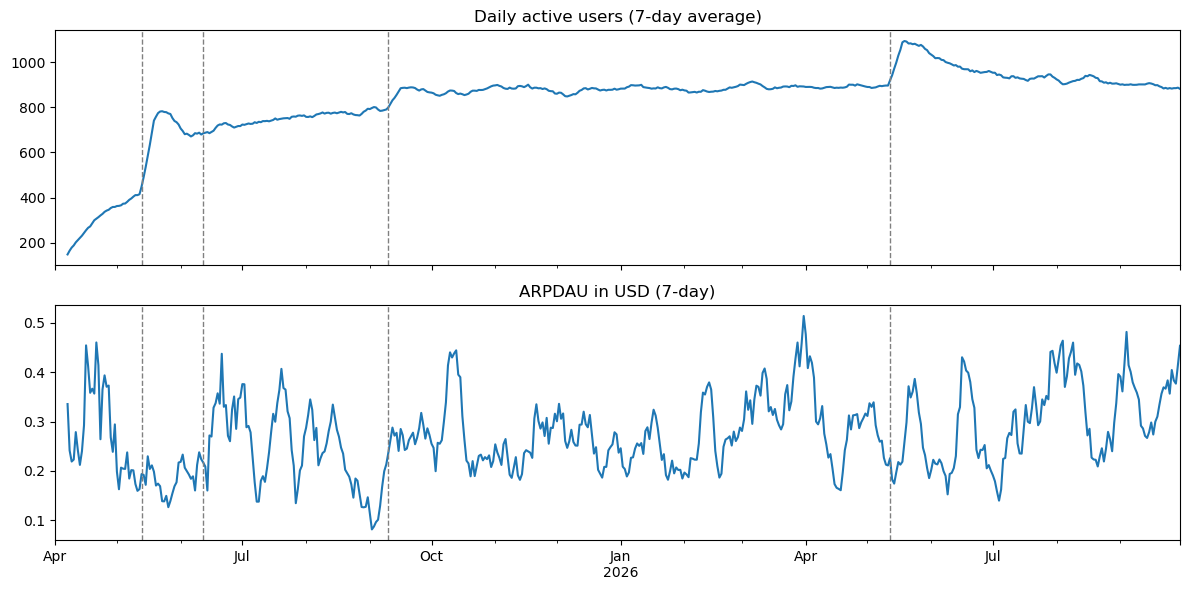

In [7]:
dau_7d    = daily["dau"].rolling(7).mean()
arpdau_7d = daily["revenue"].rolling(7).sum() / daily["dau"].rolling(7).sum()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
dau_7d.plot(ax=ax1, title="Daily active users (7-day average)")
arpdau_7d.plot(ax=ax2, title="ARPDAU in USD (7-day)")
for d in ["2025-05-13", "2025-06-12", "2025-09-10", "2026-05-12"]:
    for ax in (ax1, ax2):
        ax.axvline(pd.Timestamp(d), color="grey", linestyle="--", linewidth=1)
plt.tight_layout()
plt.show()

In [8]:
monthly = daily.resample("MS").sum()
monthly["avg_dau"] = daily["dau"].resample("MS").mean().round(0)
monthly["arpdau"]  = (monthly["revenue"] / monthly["dau"]).round(3)
monthly[["avg_dau", "revenue", "arpdau"]].round({"revenue": 0})

,avg_dau,revenue,arpdau
2025-04-01,267.0,2559.0,0.320
2025-05-01,611.0,3443.0,0.182
2025-06-01,703.0,6022.0,0.286
2025-07-01,747.0,5957.0,0.257
2025-08-01,776.0,4952.0,0.206
2025-09-01,852.0,6302.0,0.247
2025-10-01,871.0,7462.0,0.276
2025-11-01,881.0,6802.0,0.257
2025-12-01,874.0,6922.0,0.256
2026-01-01,886.0,6322.0,0.230


# M4: Whale concentration

In [9]:
spend = revenue_per_payer.sort_values(ascending=False).reset_index(drop=True)

for top in [1, 5, 10, 20, 50]:
    k = int(len(spend) * top / 100)
    print(f"Top {top:>2}% of payers ({k:>4} players): {spend.head(k).sum() / spend.sum():.0%} of revenue")

whales = revenue_per_payer[revenue_per_payer >= revenue_per_payer.quantile(0.90)]
print(f"\nWhales (top 10% of payers): {len(whales)} players = {len(whales) / len(players):.2%} of all players")
print(f"Whale threshold: ${whales.min():.2f} | whales' average spend: ${whales.mean():.0f}")

Top  1% of payers (  14 players): 17% of revenue
Top  5% of payers (  72 players): 46% of revenue
Top 10% of payers ( 144 players): 61% of revenue
Top 20% of payers ( 289 players): 76% of revenue
Top 50% of payers ( 723 players): 93% of revenue

Whales (top 10% of payers): 145 players = 0.29% of all players
Whale threshold: $179.95 | whales' average spend: $532


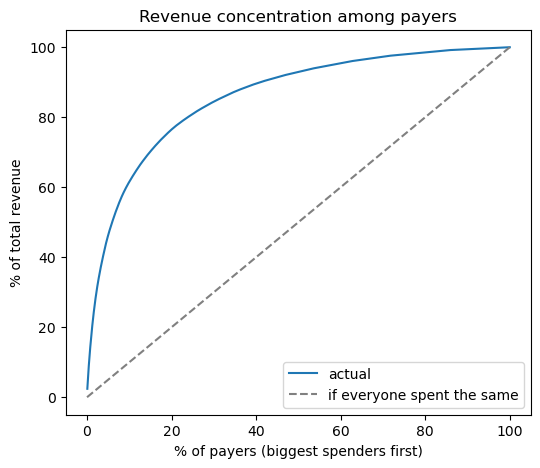

In [10]:
cum_share   = spend.cumsum() / spend.sum() * 100
payer_share = (spend.index + 1) / len(spend) * 100

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(payer_share, cum_share, label="actual")
ax.plot([0, 100], [0, 100], linestyle="--", color="grey", label="if everyone spent the same")
ax.set_xlabel("% of payers (biggest spenders first)")
ax.set_ylabel("% of total revenue")
ax.set_title("Revenue concentration among payers")
ax.legend()
plt.show()

# M5: LTV (lifetime value)

Players in the fixed group: 33505 | event: 3860 | normal: 29645


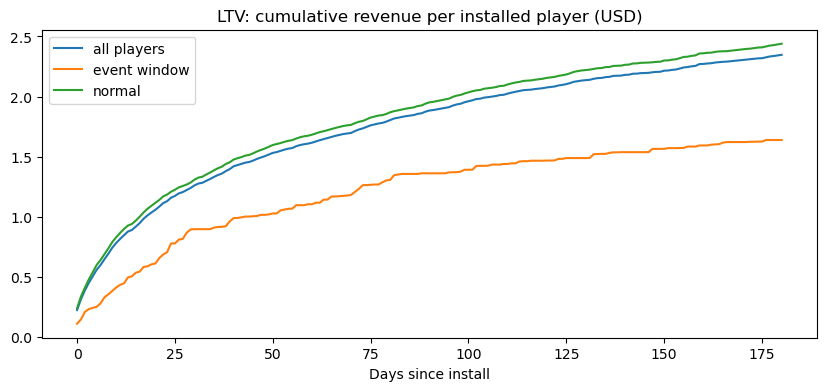

,all players,event window,normal
day_n,,,
0,0.22,0.11,0.24
7,0.65,0.33,0.69
30,1.26,0.90,1.31
90,1.88,1.36,1.95
180,2.35,1.64,2.44


In [11]:
BIG_RELEASES = ["2025-05-13", "2026-05-12"]
players["event_window"] = False
for d in BIG_RELEASES:
    start = pd.Timestamp(d)
    players.loc[(players["install_time"] >= start) &
                (players["install_time"] < start + pd.Timedelta(days=21)), "event_window"] = True

HORIZON = 180
fixed = players[players["days_observable"] >= HORIZON]          # same group at every point of the curve
pf = p[p["player_id"].isin(fixed["player_id"]) & (p["day_n"] <= HORIZON)] \
       .merge(fixed[["player_id", "event_window"]], on="player_id")

def ltv_curve(player_mask, purchase_mask):
    daily = pf[purchase_mask].groupby("day_n")["amount_usd"].sum().reindex(range(HORIZON + 1), fill_value=0)
    return daily.cumsum() / player_mask.sum()                  # cumulative revenue ÷ players in the group

ltv = pd.DataFrame({
    "all players":  ltv_curve(pd.Series(True, index=fixed.index), pd.Series(True, index=pf.index)),
    "event window": ltv_curve(fixed["event_window"], pf["event_window"]),
    "normal":       ltv_curve(~fixed["event_window"], ~pf["event_window"]),
})
print("Players in the fixed group:", len(fixed), "| event:", fixed["event_window"].sum(),
      "| normal:", (~fixed["event_window"]).sum())

ax = ltv.plot(figsize=(10, 4), title="LTV: cumulative revenue per installed player (USD)")
ax.set_xlabel("Days since install")
plt.show()
ltv.loc[[0, 7, 30, 90, 180]].round(2)

# M6: Summary of findings
## Summary: monetization (synthetic data)

**Note:** synthetic data modeled on Palia; results demonstrate the methods.

### Findings
1. **Conversion:** 2.9% of players paid (benchmark range 2–4%). About 64% of payers made
   their first purchase within the first week, and 30% on their install day.
   
2. **ARPU vs ARPPU:** $2.50 per player vs $86.56 per payer. The median payer spent only
   $24.97, so the average payer is not a typical payer.

   
3. **Pack mix:** the $4.99 pack is the most bought (36% of purchases, 8% of revenue);
   the $99.99 pack the least bought (9% of purchases, 40% of revenue).

   
4. **Whales:** the top 10% of payers (145 players, 0.29% of all players) brought 61% of
   revenue; the top 14 players alone brought 17%.

   
5. **ARPDAU:** $0.28 overall. Big releases raise DAU but dilute ARPDAU at first
   (May 2025: DAU doubled while ARPDAU fell from $0.32 to $0.18).

   
6. **LTV:** $1.26 after 30 days and $2.35 after 180 days per installed player.
   Players acquired around big releases are worth about 33% less ($1.64 vs $2.44 at day 180).

### Methods worth noting
- Medians reported next to averages, because spending is highly skewed.
- ARPDAU smoothed as 7-day revenue ÷ 7-day DAU, and reported monthly, because daily values are noisy.
- LTV curves use a fixed group of players (observable for all 180 days), so the curve
  cannot drop when recent cohorts would otherwise leave the group.

### Implications
- The first week decides both retention and first purchases: onboarding and early offers matter most.
- Revenue depends on very few players: whale-relevant content and support are worth investing in,
  without designing the game only around them.
- Paid acquisition is only profitable below about $2.35 per install (6-month LTV), and lower for
  campaigns that bring event-style "tourist" players.

### Limitations
- Synthetic data; the spending model is based on mobile benchmarks.
- The first months are a warm-up: the simulated game starts with zero players.
- Small groups (event cohorts, whales) are noisy.

In [12]:
import os
OUT = "data/powerbi"
os.makedirs(OUT, exist_ok=True)

# 1. Purchases: one row per purchase (the interactive "fact" table)
fact_purchases = p[["player_id", "purchase_time", "amount_usd", "day_n"]] \
                   .rename(columns={"day_n": "days_since_install"})
fact_purchases["purchase_date"] = fact_purchases["purchase_time"].dt.date
fact_purchases.drop(columns="purchase_time").to_csv(f"{OUT}/fact_purchases.csv", index=False)

# 2. Daily DAU and revenue (Power BI will calculate ARPDAU and 7-day averages)
daily.astype({"dau": int}).rename_axis("date").reset_index() \
     .to_csv(f"{OUT}/daily_kpis.csv", index=False)

# 3. Whale curve: cumulative revenue share by payer rank
pd.DataFrame({"payer_share_pct": payer_share.round(3),
              "revenue_share_pct": cum_share.round(3)}) \
  .to_csv(f"{OUT}/whale_curve.csv", index=False)

# 4. LTV curves, long format (one row per day and group)
ltv.rename_axis("day").reset_index() \
   .melt(id_vars="day", var_name="group", value_name="ltv_usd").round(3) \
   .to_csv(f"{OUT}/ltv_curve.csv", index=False)

print("Saved:", sorted(os.listdir(OUT)))

Saved: ['churn_timing.csv', 'daily_kpis.csv', 'fact_purchases.csv', 'ltv_curve.csv', 'retention_cohorts.csv', 'retention_curve.csv', 'retention_event_vs_normal.csv', 'whale_curve.csv']
